# Day 15

## Feature Engineering

In [ ]:
# Data transformation/pre-processing

# Standardisation
# Normalisation

In [30]:
import pandas as pd, numpy as np
from sklearn.preprocessing import StandardScaler, minmax_scale
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv('../Day 14/churn.csv')

In [3]:
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [9]:
df.iloc[0:1]

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.0,1,1,1,101348.88,1


In [11]:
manual_ss = (df.iloc[:1].EstimatedSalary - df.EstimatedSalary.mean())/df.EstimatedSalary.std()
manual_ss

0    0.021885
Name: EstimatedSalary, dtype: float64

In [13]:
ss = StandardScaler()

In [15]:
ss = ss.fit_transform(df.EstimatedSalary.values.reshape(-1,1))
ss

array([[ 0.02188649],
       [ 0.21653375],
       [ 0.2406869 ],
       ...,
       [-1.00864308],
       [-0.12523071],
       [-1.07636976]], shape=(10000, 1))

In [17]:
mm = minmax_scale(df.EstimatedSalary.values.reshape(-1,1))
mm

array([[0.50673489],
       [0.56270874],
       [0.56965435],
       ...,
       [0.21039009],
       [0.46442905],
       [0.19091423]], shape=(10000, 1))

C:\Users\10880893\AppData\Local\Temp\ipykernel_22260\448607350.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(ss)


<Axes: ylabel='Density'>

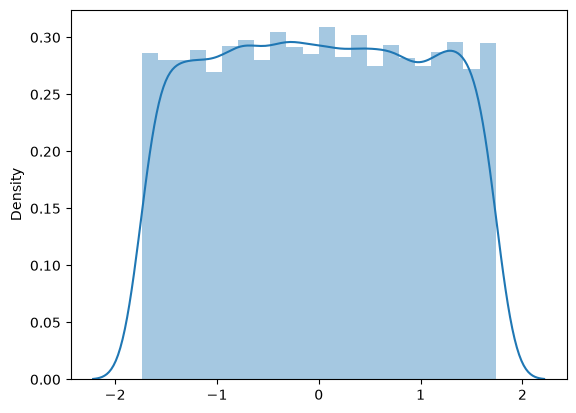

In [24]:
sns.distplot(ss)

In [35]:
x = x = df.iloc[:,2:-1]
x = pd.get_dummies(x, columns=['Geography','Gender'],drop_first=True)
x

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [34]:
y = df['Exited']
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

## Class Imbalance

In [28]:
s = SMOTE()

In [36]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=7)

In [37]:
xtrainSMOTE,ytrainSMOTE, = s.fit_resample(xtrain,ytrain)